# Analisis Kesehatan Baterai EV: Transformasi Data Menjadi Informasi & Informasi Strategis
**Berdasarkan Hasil Eksplorasi Dataset Baterai Kendaraan Listrik (`ev_battery_health.csv`)**

> **Satuan analisis:** dataset berisi 50.000 baris observasi dari 2.600 paket baterai (`battery_id`), dan tiap baterai diukur berulang kali. Karena itu perbandingan antar kelompok dilakukan **per baterai**, bukan per baris observasi.

---
## Kerangka Piramida DIKW (*Data - Information - Knowledge/Strategic Information*)
| Lapisan Analitik | Tahapan dalam Notebook | Pertanyaan yang Dijawab | Output Utama |
| :--- | :--- | :--- | :--- |
| **1. FASE PRA-PEMROSESAN DATA (*Data Preparation*)** | **Tahap 1:** Ekstraksi, Pembersihan, & Rekayasa Fitur Dasar | *"Apakah data log baterai valid, konsisten, dan siap diolah?"* | Data bersih pada level observasi dan level baterai. |
| **2. FASE INFORMASI (*Descriptive Information*)** | **Tahap 2 & 3:** Profil Degradasi SOH | *"Apa yang sedang/sudah terjadi dengan degradasi SOH berdasarkan jenis baterai dan kebiasaan charging?"* | Fakta terukur: LFP paling awet, LMO paling cepat turun. |
| **3. FASE INFORMASI STRATEGIS (*Strategic & Prescriptive Information*)** | **Tahap 4 & 5:** Dampak Fast Charge & Rekomendasi Operasional | *"Keputusan alokasi dan protokol charging apa yang didukung data?"* | LFP untuk beban berat, prioritaskan pemantauan LMO/NCA, kurangi porsi fast charge. |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 50)
sns.set_theme(style='whitegrid', palette='muted')

# 0. Memuat Dataset Mentah (Raw Data)
df_raw = pd.read_csv('../ev_battery_health.csv')
df_raw['observation_date'] = pd.to_datetime(df_raw['observation_date'], errors='coerce')

---
# BAGIAN I: FASE PRA-PEMROSESAN DATA (*DATA PREPARATION PHASE*)
> **Tujuan Fase Ini:** Membersihkan log data sensor baterai, menyaring anomali (SOH > 100%, suhu tidak masuk akal), membuat fitur kategorikal, lalu meringkas data menjadi **satu baris per baterai**.
>
> **Catatan:** `degradation_category` dan `failure_risk_label` **tidak dipakai** sebagai hasil utama karena keduanya pada dasarnya hanyalah label yang diturunkan dari rentang SOH (Normal ≥ 80%, Accelerated ± 70–80%, Critical < 70%). Hasil analisis memakai SOH langsung.

In [2]:
# Tahap 1. Pembersihan Data & Pembuatan Kategori

df = (
    df_raw
    .drop_duplicates('observation_id')
    .assign(chemistry=lambda d: d.groupby('battery_id')['chemistry'].transform(lambda s: s.ffill().bfill()),
            avg_ambient_temp_c=lambda d: d['avg_ambient_temp_c'].where(d['avg_ambient_temp_c'].between(-40, 60)))
    .dropna(subset=['chemistry', 'cycle_count', 'state_of_health_pct'])
    .query('0 < state_of_health_pct <= 100 and cycle_count > 0')
    .rename(columns={'chemistry': 'Battery_Type', 'cycle_count': 'Cycle_Count', 'state_of_health_pct': 'State_of_Health',
                    'fast_charge_ratio': 'Fast_Charge_Ratio', 'avg_ambient_temp_c': 'Temperature'})
    .assign(Temp_Category=lambda d: pd.cut(d['Temperature'], bins=[-np.inf, 20, 35, np.inf],
                                        labels=['Rendah (<20C)', 'Normal (20-35C)', 'Tinggi (>35C)']))
)

fast, std = 'Aggressive Fast Charge', 'Standard/Slow Charge'
# Siklus tertinggi menjadi acuan; tanggal dan ID memecah seri secara konsisten.
bat = (
    df.sort_values(
        ['Cycle_Count', 'observation_date', 'observation_id'],
        na_position='first',
    ).groupby('battery_id')
    .agg(Battery_Type=('Battery_Type', 'first'), Cycle_Max=('Cycle_Count', 'max'), SOH_Akhir=('State_of_Health', 'last'),
        Fast_Charge_Mean=('Fast_Charge_Ratio', 'mean'), Jumlah_Observasi=('Cycle_Count', 'size'))
    .assign(Charging_Behavior=lambda d: np.where(d['Fast_Charge_Mean'] > 0.4, fast, std),
            SOH_Loss_per_1000_Cycles=lambda d: ((100 - d['SOH_Akhir']) / d['Cycle_Max'] * 1000).where(d['Cycle_Max'] >= 100))
)

audit = pd.Series({
    'Baris observasi mentah': len(df_raw),
    'Baris observasi dipakai': len(df),
    'Baris dibuang (tanpa jumlah siklus / SOH tidak valid)': len(df_raw) - len(df),
    'Nilai suhu tidak masuk akal -> NaN': int((df_raw['avg_ambient_temp_c'].notna() & ~df_raw['avg_ambient_temp_c'].between(-40, 60)).sum()),
    'Jumlah baterai (satuan analisis)': len(bat),
}).to_frame('Jumlah')
print("=== AUDIT DATA BATERAI ===")
print(audit.to_string())
print("\nBaterai per tipe     :", bat['Battery_Type'].value_counts().to_dict())
print("Baterai per charging :", bat['Charging_Behavior'].value_counts().to_dict())

=== AUDIT DATA BATERAI ===
                                                       Jumlah
Baris observasi mentah                                  50000
Baris observasi dipakai                                 47731
Baris dibuang (tanpa jumlah siklus / SOH tidak valid)    2269
Nilai suhu tidak masuk akal -> NaN                         37
Jumlah baterai (satuan analisis)                         2600

Baterai per tipe     : {'NMC': 890, 'LFP': 784, 'NCA': 545, 'LMO': 381}
Baterai per charging : {'Standard/Slow Charge': 1948, 'Aggressive Fast Charge': 652}


---
# BAGIAN II: FASE INFORMASI (*DESCRIPTIVE INFORMATION PHASE*)
> **Apa itu Fase Informasi?**
> Fase **Informasi** menjawab pertanyaan **"Apa yang sedang/sudah terjadi dengan baterai kita?" (*What is happening?*)**.

---
## Tahap 2 & 3 [FASE INFORMASI]: Profil Degradasi SOH Berdasarkan Tipe Baterai & Perilaku Charging

### Temuan Utama (*Insight*):
1. **Karakteristik Jenis Baterai (temuan paling kuat):**
   * Jenis baterai adalah faktor yang paling jelas membedakan ketahanan umur pakai.
   * **LFP** paling awet. **LMO** mengalami penurunan SOH tercepat. **NMC** dan **NCA** berada di tengah.
2. **Dampak Pengisian Cepat (*Fast Charge*):**
   * Pada jumlah siklus yang sama, baterai dengan porsi fast charge tinggi memiliki SOH **sedikit lebih rendah** (sekitar 0,3–1,1 poin), dan arah ini terlihat pada semua tipe.
   * Data **tidak cukup membuktikan** bahwa LMO dan NCA lebih rentan terhadap fast charge dibanding tipe lain.

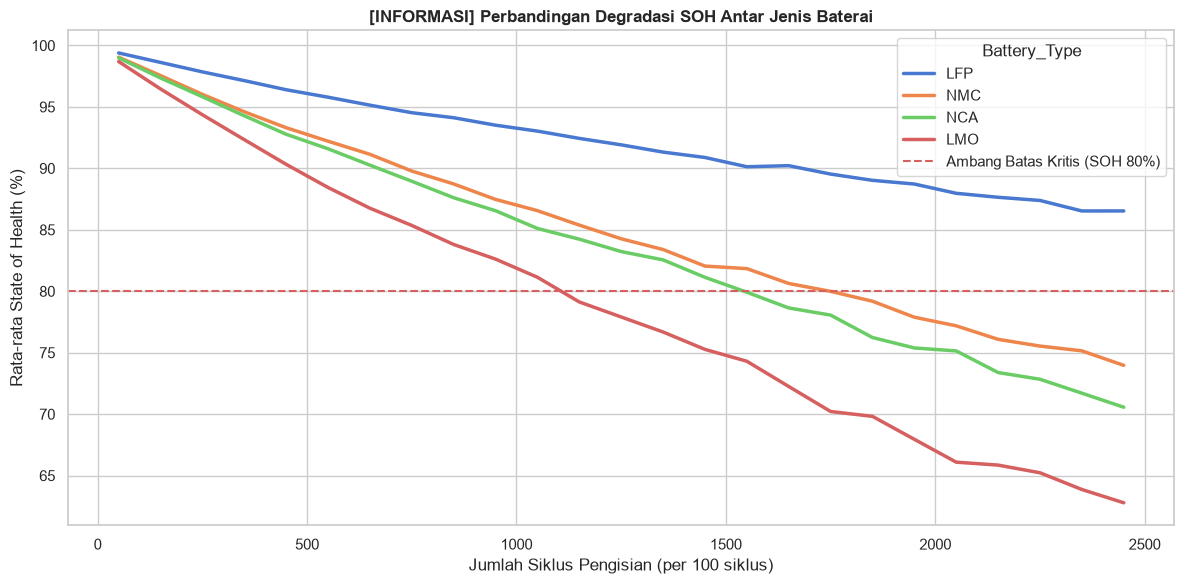

[INFORMASI] Profil Degradasi SOH per Jenis Baterai (satuan: baterai, urut dari paling awet):
              Jumlah_Baterai  SOH_Terakhir_Median  Kehilangan_SOH_per_1000_Siklus  Pct_Baterai_SOH_di_Bawah_80  Siklus_Kurva_Mencapai_SOH80
Battery_Type                                                                                                                               
LFP                      784                 93.3                             7.6                          0.6                        >2500
NMC                      890                 87.8                            14.1                         23.1                       1750.0
NCA                      545                 84.8                            15.2                         31.2                       1550.0
LMO                      381                 82.2                            20.1                         43.8                       1150.0

[INFORMASI] Paling awet: LFP | Paling cepat menurun: LMO (2.6x laj

In [3]:
# Tahap 2 & 3 [FASE INFORMASI]: Visualisasi Tren Degradasi

trend = df.query('Cycle_Count < 2500').assign(Cycle_Bin=lambda d: d['Cycle_Count'] // 100 * 100 + 50)

plt.figure(figsize=(12, 6))
sns.lineplot(data=trend, x='Cycle_Bin', y='State_of_Health', hue='Battery_Type',
          hue_order=['LFP', 'NMC', 'NCA', 'LMO'], errorbar=None, linewidth=2.5)
plt.axhline(y=80, color='r', linestyle='--', label='Ambang Batas Kritis (SOH 80%)')
plt.title('[INFORMASI] Perbandingan Degradasi SOH Antar Jenis Baterai', fontweight='bold')
plt.ylabel('Rata-rata State of Health (%)')
plt.xlabel('Jumlah Siklus Pengisian (per 100 siklus)')
plt.legend(title='Battery_Type')
plt.tight_layout()
plt.show()

curve = trend.pivot_table(index='Cycle_Bin', columns='Battery_Type', values='State_of_Health')
info = (bat.groupby('Battery_Type')
          .agg(Jumlah_Baterai=('SOH_Akhir', 'size'),
               SOH_Terakhir_Median=('SOH_Akhir', 'median'),
               Kehilangan_SOH_per_1000_Siklus=('SOH_Loss_per_1000_Cycles', 'mean'),
                Pct_Baterai_SOH_di_Bawah_80=('SOH_Akhir', lambda s: (s < 80).mean() * 100))
          .assign(Siklus_Kurva_Mencapai_SOH80=curve.lt(80).idxmax().where(curve.lt(80).any()))
          .sort_values('Kehilangan_SOH_per_1000_Siklus')
          .round(1))
print("[INFORMASI] Profil Degradasi SOH per Jenis Baterai (satuan: baterai, urut dari paling awet):")
print(info.to_string(na_rep='>2500'))
print(f"\n[INFORMASI] Paling awet: {info.index[0]} | Paling cepat menurun: {info.index[-1]} "
     f"({info['Kehilangan_SOH_per_1000_Siklus'].iloc[-1] / info['Kehilangan_SOH_per_1000_Siklus'].iloc[0]:.1f}x laju {info.index[0]})")

---
# BAGIAN III: FASE INFORMASI STRATEGIS (*STRATEGIC & PRESCRIPTIVE INFORMATION PHASE*)
> **Apa itu Fase Informasi Strategis?**
> Fase ini menerjemahkan fakta menjadi keputusan, menjawab **"Tindakan strategis apa yang harus dieksekusi?" (*So What & Now What?*)**.

---
## Tahap 4 & 5 [FASE INFORMASI STRATEGIS]: Rekomendasi Alokasi & Kebijakan Operasional

### 1. Strategi Pemilihan & Alokasi Baterai
* **Beban berat / intensitas tinggi:** gunakan **LFP**. Dukungan data **kuat**.
* **Prioritas pemantauan, penggantian, dan *second-life*:** **LMO**, lalu **NCA**, karena paling banyak baterainya yang sudah di bawah SOH 80%. Dukungan data **kuat** (berdasarkan jenis baterai).

### 2. Protokol Pengisian Daya (*Charging Policy*)
* Kurangi porsi *fast charge* pada **semua tipe**, karena arah dampaknya konsisten merugikan. Dukungan data **sedang**: efeknya kecil dan bukti sebab-akibat belum ada.
* Angka **40%** adalah ketentuan awal, bukan hasil temuan. Pada LFP, NMC, dan NCA, SOH turun **bertahap** seiring naiknya porsi fast charge, tanpa batas tajam di 40%. Pada LMO polanya tidak konsisten (sampel kecil).

In [4]:
# Tahap 4 & 5 [FASE INFORMASI STRATEGIS]:
# Siklus disamakan: SOH dibandingkan di dalam kelompok siklus yang sama

BAND_LABELS = ['≤20%', '20–40%', '40–60%', '>60%']

bat = bat.assign(
    Cycle_Strata=pd.cut(bat['Cycle_Max'], [0, 500, 1000, 1500, 2000, np.inf]),
    FC_Band=pd.cut(bat['Fast_Charge_Mean'], [0, .2, .4, .6, 1], labels=BAND_LABELS))

def adj_mean(d, w):
    """Rata-rata SOH per kelompok siklus, dibobot dengan komposisi siklus w."""
    m = d.groupby('Cycle_Strata', observed=True)['SOH_Akhir'].mean().reindex(w.index).dropna()
    return (m * w[m.index]).sum() / w[m.index].sum()

def fast_vs_std(d):
    """Selisih SOH: baterai fast charge dikurangi standar, siklus disamakan."""
    w = d['Cycle_Strata'].value_counts()
    return adj_mean(d[d['Charging_Behavior'] == fast], w) - adj_mean(d[d['Charging_Behavior'] == std], w)

#Selisih SOH fast charge vs standar
rng = np.random.default_rng(42)

def ci95(d, n=500):
    boot = [fast_vs_std(d.sample(frac=1, replace=True, random_state=rng)) for _ in range(n)]
    return np.nanpercentile(boot, [2.5, 97.5])

rows = [(t, (d['Charging_Behavior'] == fast).sum(), (d['Charging_Behavior'] == std).sum(), fast_vs_std(d), *ci95(d))
        for t, d in bat.groupby('Battery_Type')]

policy_matrix = (
    pd.DataFrame(rows, columns=['Battery_Type', 'Baterai_Fast', 'Baterai_Standar', 'Selisih_SOH_poin', 'CI95_bawah', 'CI95_atas'])
    .set_index('Battery_Type')
    .assign(Kesimpulan=lambda d: np.select(
        [d['CI95_atas'] < 0, d['CI95_bawah'] > 0],
        ['SOH lebih rendah (CI tidak mencakup 0)', 'SOH lebih tinggi (CI tidak mencakup 0)'],
        default='Belum terbukti (CI mencakup 0)'))
    .sort_values('Selisih_SOH_poin').round(2))

print("[INFORMASI] Seberapa rendah SOH baterai yang sering fast charge?")
print("Dibandingkan baterai yang jarang fast charge, pada jumlah siklus yang sama:\n")

for jenis, r in policy_matrix.iterrows():
    selisih = r["Selisih_SOH_poin"]

    if r["CI95_atas"] < 0:
        hasil = f"sekitar {abs(selisih):.2f} poin lebih rendah"
        kepastian = "CI 95% tidak mencakup nol"
    elif r["CI95_bawah"] > 0:
        hasil = f"sekitar {selisih:.2f} poin lebih tinggi"
        kepastian = "CI 95% tidak mencakup nol"
    else:
        hasil = f"estimasi selisih {selisih:+.2f} poin"
        kepastian = "belum meyakinkan karena CI 95% mencakup nol"

    print(f"- {jenis}: {hasil} ({kepastian})")

[INFORMASI] Seberapa rendah SOH baterai yang sering fast charge?
Dibandingkan baterai yang jarang fast charge, pada jumlah siklus yang sama:

- NMC: sekitar 1.15 poin lebih rendah (CI 95% tidak mencakup nol)
- LMO: estimasi selisih -1.04 poin (belum meyakinkan karena CI 95% mencakup nol)
- NCA: estimasi selisih -0.72 poin (belum meyakinkan karena CI 95% mencakup nol)
- LFP: sekitar 0.35 poin lebih rendah (CI 95% tidak mencakup nol)


In [5]:
#Tahap 5: Ringkasan SOH menurut kelompok porsi fast charge
band = pd.DataFrame(
    [(t, b, adj_mean(g, d['Cycle_Strata'].value_counts()), len(g))
    for t, d in bat.groupby('Battery_Type') for b, g in d.groupby('FC_Band', observed=True)],
    columns=['Battery_Type', 'FC_Band', 'SOH_Terkoreksi', 'N_Baterai'])

print("[INFORMASI] SOH terkoreksi siklus menurut porsi fast charge (poin %):")
print(band.pivot(index='Battery_Type', columns='FC_Band', values='SOH_Terkoreksi')
        .round(2).reindex(columns=BAND_LABELS).to_string())

[INFORMASI] SOH terkoreksi siklus menurut porsi fast charge (poin %):
FC_Band        ≤20%  20–40%  40–60%   >60%
Battery_Type                              
LFP           92.86   92.84   92.49  92.45
LMO           80.57   80.48   79.74  81.34
NCA           84.43   83.96   83.44  83.31
NMC           86.78   86.42   85.58  84.83


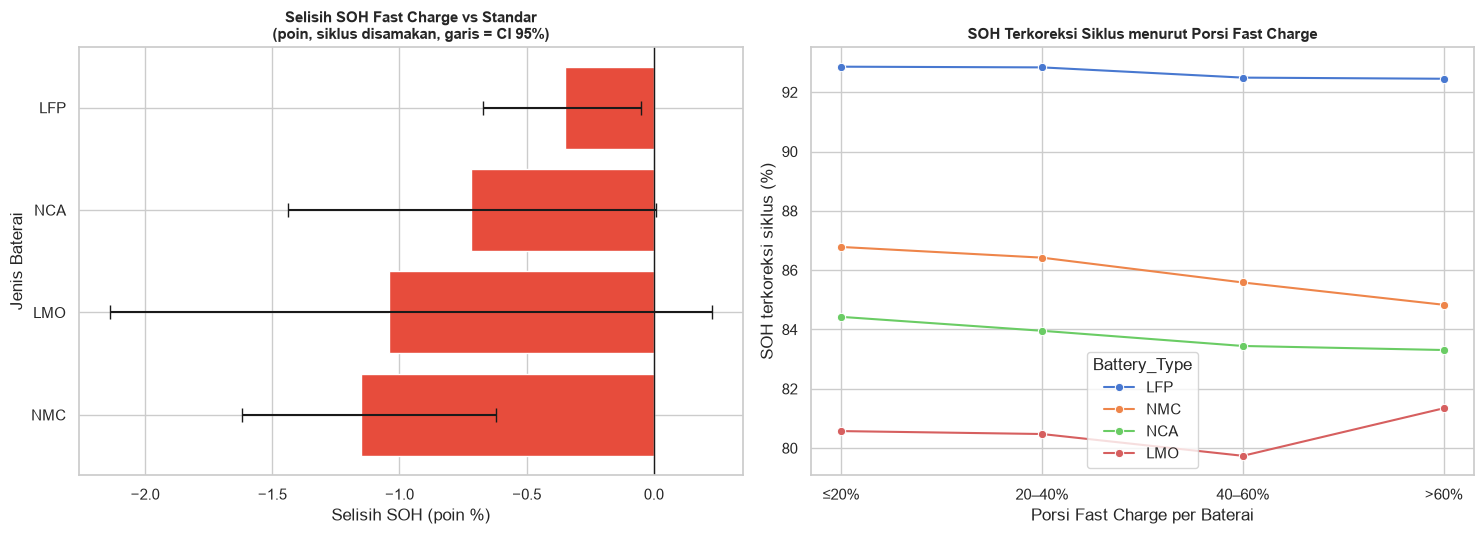

In [6]:
## Visualisasi: selisih SOH dan tren menurut porsi fast charge
pm = policy_matrix
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5.5))

a1.barh(pm.index, pm['Selisih_SOH_poin'], color='#e74c3c',
        xerr=[pm['Selisih_SOH_poin'] - pm['CI95_bawah'], pm['CI95_atas'] - pm['Selisih_SOH_poin']], capsize=5)
a1.axvline(0, color='k', linewidth=1)
a1.set_title('Selisih SOH Fast Charge vs Standar\n(poin, siklus disamakan, garis = CI 95%)',
        fontweight='bold', fontsize=11)
a1.set_xlabel('Selisih SOH (poin %)')
a1.set_ylabel('Jenis Baterai')

sns.lineplot(data=band, x='FC_Band', y='SOH_Terkoreksi', hue='Battery_Type', marker='o',
        ax=a2, hue_order=['LFP', 'NMC', 'NCA', 'LMO'])
a2.set_title('SOH Terkoreksi Siklus menurut Porsi Fast Charge',
        fontweight='bold', fontsize=11)
a2.set_xlabel('Porsi Fast Charge per Baterai')
a2.set_ylabel('SOH terkoreksi siklus (%)')

plt.tight_layout()
plt.show()

In [7]:
# Ringkasan strategi berdasarkan hasil analisis
best, worst = info.index[0], info.index[-1]
prior = info['Pct_Baterai_SOH_di_Bawah_80'].sort_values(ascending=False)

print("[INFORMASI STRATEGIS] STRATEGI YANG DIDUKUNG DATA")
print(f"1. ALOKASI -> Pakai {best} untuk beban berat. Hanya {info.loc[best, 'Pct_Baterai_SOH_di_Bawah_80']:.1f}% baterai {best} "
      f"sudah di bawah SOH 80%, vs {info.loc[worst, 'Pct_Baterai_SOH_di_Bawah_80']:.1f}% pada {worst}.")
print(f"2. PEMANTAUAN / SECOND-LIFE -> Prioritas {prior.index[0]}, lalu {prior.index[1]}: "
      f"{prior.iloc[0]:.1f}% dan {prior.iloc[1]:.1f}% baterainya sudah di bawah SOH 80%.")
print(f"3. CHARGING -> Kurangi porsi fast charge pada semua tipe: SOH baterai fast charge lebih rendah "
      f"{-pm['Selisih_SOH_poin'].max():.1f}-{-pm['Selisih_SOH_poin'].min():.1f} poin pada siklus yang sama. "
      f"Efek kecil, bukti sebab-akibat belum ada, dan batas 40% tidak teruji.")

[INFORMASI STRATEGIS] STRATEGI YANG DIDUKUNG DATA
1. ALOKASI -> Pakai LFP untuk beban berat. Hanya 0.6% baterai LFP sudah di bawah SOH 80%, vs 43.8% pada LMO.
2. PEMANTAUAN / SECOND-LIFE -> Prioritas LMO, lalu NCA: 43.8% dan 31.2% baterainya sudah di bawah SOH 80%.
3. CHARGING -> Kurangi porsi fast charge pada semua tipe: SOH baterai fast charge lebih rendah 0.3-1.1 poin pada siklus yang sama. Efek kecil, bukti sebab-akibat belum ada, dan batas 40% tidak teruji.


---
# KESIMPULAN: DARI INFORMASI KE INFORMASI STRATEGIS

## A. Informasi (*Apa yang Terjadi?*)

**1. Jenis baterai paling menentukan umur pakai.**

| Jenis | Kehilangan SOH per 1000 siklus | SOH terakhir (median) | Baterai di bawah SOH 80% | Estimasi siklus mencapai SOH 80% |
| :--- | :---: | :---: | :---: | :---: |
| **LFP** | 7,6 poin | 93,3% | 0,6% | Belum tercapai hingga 2500 siklus |
| **NMC** | 14,1 poin | 87,8% | 23,1% | ~1750 |
| **NCA** | 15,2 poin | 84,8% | 31,2% | ~1550 |
| **LMO** | 20,1 poin | 82,2% | 43,8% | ~1150 |

* **LFP paling awet. LMO paling cepat turun**, sekitar 2,6x laju LFP. NMC dan NCA berada di tengah.

**2. Pengaruh fast charge (>40%) terhadap SOH.**

* Pada jumlah siklus yang sama, baterai dengan porsi fast charge tinggi memiliki SOH yang sedikit lebih rendah, dengan selisih sekitar **0,3–1,1 poin** di semua jenis baterai.
* Selisih paling konsisten terlihat pada **NMC** (-1,14 poin) dan **LFP** (-0,35 poin).
* **LMO** (-1,05 poin): arah selisihnya sama, tetapi rentang kepercayaan 95% mencakup nol sehingga besarnya belum pasti.
* **NCA** (-0,75 poin): selisihnya berada tepat di perbatasan, dengan batas atas rentang kepercayaan sangat dekat dengan nol.
* Selisih akibat fast charge (0,3–1,1 poin) jauh lebih kecil daripada selisih antar jenis baterai. Sebagai pembanding, SOH akhir median LFP 93,3% sedangkan LMO 82,2%.

---

## B. Informasi Strategis (*Keputusan yang Didukung Data*)

**1. Pilih LFP untuk pemakaian berat.**
LFP paling tahan lama. Baru 0,6% baterai LFP yang SOH-nya turun di bawah 80%, sedangkan pada LMO angkanya 43,8%. Jadi LFP paling aman untuk rute berat atau baterai yang sering fast charge. *(Dukungan data: kuat)*

**2. Prioritaskan LMO dan NCA untuk pemantauan, penggantian, atau *second-life*.**
Kedua jenis ini paling banyak yang SOH-nya sudah di bawah 80%, yaitu 43,8% pada LMO dan 31,2% pada NCA. Baterai yang sudah di bawah 80% perlu dinilai untuk diganti atau dipakai ulang sebagai penyimpan daya non-kendaraan (*second-life*). *(Dukungan data: kuat)*

**3. Kurangi porsi fast charge pada semua jenis baterai.**
Pada jumlah siklus yang sama, baterai dengan porsi fast charge tinggi memiliki SOH sedikit lebih rendah, yaitu sekitar 0,3–1,1 poin. Pola ini terlihat di semua jenis baterai, jadi pengurangan fast charge berlaku untuk semuanya, bukan hanya jenis tertentu. Penurunan terjadi bertahap seiring naiknya porsi fast charge, sehingga angka 40% lebih tepat dipakai sebagai target awal, bukan batas pasti. *(Dukungan data: sedang, karena selisihnya kecil)*

---

## Tabel Perbandingan Skenario Strategis Kebijakan Baterai

| Dimensi Kebijakan | Skenario A: "Durability First" | Skenario B: "Chemistry-Led & Flexible Charging" |
| :--- | :--- | :--- |
| **Fokus Prioritas** | Memperpanjang umur pakai lewat pemilihan jenis baterai **dan** disiplin pengisian | Memperpanjang umur pakai lewat pemilihan jenis baterai, tanpa membatasi pengisian |
| **Alokasi Jenis Baterai** | LFP untuk pemakaian berat; LMO dan NCA diprioritaskan untuk pemantauan dan *second-life* | LFP untuk rute dengan fast charge intensif; LMO dan NCA dipakai di rute ringan dan dipantau |
| **Kebijakan Fast Charge** | Porsi fast charge dikurangi di semua jenis, target awal di bawah 40% | Fast charge tidak dibatasi, terutama pada LFP |
| **Dasar dari Data** | Fast charge berasosiasi dengan SOH 0,3–1,1 poin lebih rendah di semua jenis, sehingga mengurangi porsinya menutup selisih itu | Selisih antar jenis (LFP vs LMO ± 11 poin) jauh lebih besar dari selisih fast charge (0,3–1,1 poin). Pada LFP, selisih fast charge hanya 0,35 poin |
| **Dampak pada Umur Pakai** | Potensi SOH 0,3–1,1 poin lebih tinggi pada siklus yang sama, dengan catatan sebab-akibat belum terbukti | Umur pakai ditentukan terutama oleh jenis baterai; SOH ± 0,3–1,1 poin lebih rendah pada yang sering fast charge diterima sebagai trade-off |
| **Dampak pada Operasional** | Waktu pengisian lebih lama dan jadwal armada perlu disesuaikan | Jadwal pengisian tetap fleksibel dan waktu henti kendaraan lebih singkat |
| **Hal yang Tidak Bisa Dinilai dari Data** | Biaya penyesuaian jadwal, biaya LFP vs jenis lain | Biaya penggantian lebih awal, kapasitas energi per bobot LFP |

---
### Rincian Eksekusi Strategis

**1. Skenario A: Durability First**
* **Logika Bisnis:** Dua langkah dilakukan bersamaan: memakai jenis yang paling tahan lama dan mengurangi porsi fast charge. Keduanya mengarah ke SOH yang lebih tinggi.
* **Rekomendasi Operasional:** Alokasikan LFP untuk rute berat, pantau LMO dan NCA yang mendekati SOH 80%, dan turunkan porsi fast charge secara bertahap.

**2. Skenario B: Chemistry-Led & Flexible Charging**
* **Logika Bisnis:** Data menunjukkan jenis baterai memengaruhi SOH jauh lebih besar daripada fast charge. Karena itu upaya difokuskan pada pemilihan jenis, sementara pengisian dibiarkan fleksibel supaya operasional tidak terhambat.
* **Rekomendasi Operasional:** Tempatkan LFP pada rute yang sering fast charge, karena dampaknya pada LFP paling kecil. Pakai LMO dan NCA pada rute ringan, dan pantau yang sudah mendekati SOH 80%.